# Proyecto Final SINF-633: Descubrimiento de Conocimiento en Bases de Datos (KDD) para la Prevención de Fraude Bancario en Costa Rica

**Rol:** Analista Sénior de Prevención de Fraude — Entidad Bancaria Costarricense  
**Metodología:** Proceso KDD Canónico de Fayyad et al. (1996) *(Selección, Preprocesamiento, Transformación, Minería de Datos e Interpretación/Evaluación)*  
**Dataset:** `transacciones_bancarias.csv` (5 000 registros transaccionales, 11 variables)

---

### Pregunta Central del Proyecto
> *¿Qué patrones permiten distinguir transacciones bancarias legítimas de fraudulentas, y cómo puede el banco operacionalizar esos patrones para reducir pérdidas sin degradar la experiencia del cliente legítimo?*

### Resumen de la Estructura del Notebook
1. **Etapa 1 · Selección (10 pts):** Carga con `parse_dates=['fecha_hora']`, tipología documental de las 11 variables, criterios justificados de inclusión/exclusión y análisis del desbalance de clases (2.18 % de tasa global de fraude).
2. **Etapa 2 · Preprocesamiento (15 pts):** Diagnóstico e imputación justificada de valores nulos, análisis estadístico de *outliers* mediante rango intercuartílico ($	ext{IQR}, k=1.5$), comparación de tasas de fraude en valores extremos, verificación de duplicados y corrección de asimetría con `np.log1p()`.
3. **Etapa 3 · Transformación (15 pts):** Ingeniería de atributos (creación de 5 variables derivadas incluyendo `hora_dia`, `es_noche`, `monto_log`, `interaccion_noche_monto` y `ratio_monto_antiguedad`), codificación `pd.get_dummies(drop_first=True)` / `OneHotEncoder(drop='first')`, escalamiento libre de *data leakage* con `StandardScaler`, análisis de multicolinealidad ($|r| > 0.8$) y encapsulamiento en un `Pipeline` reproducible de `scikit-learn`.
4. **Etapa 4 · Minería de Datos (25 pts + 5 pts Bonus):**
   - **No Supervisada:** Clustering con **K-Means** ($k \in [2, 10]$, método del codo e índice de silueta), detección de anomalías por densidad con **DBSCAN**, reducción de dimensionalidad con **PCA** (2 y 3 componentes) y **Bonus (+5 pts)** de reglas de asociación con **Apriori** ($	ext{lift} > 1.5$).
   - **Supervisada:** Partición estratificada 80/20 (`stratify=y`, `random_state=42`) y entrenamiento de tres arquitecturas: **Regresión Logística (`class_weight='balanced'`)**, **Random Forest** y **XGBoost (Modelo Bonus)**, evaluadas con `Accuracy`, `Precision`, `Recall`, `F1-Score` y `AUC-ROC`.
5. **Etapa 5 · Interpretación y Visualización (15 pts):** Matrices de confusión con `sns.heatmap()`, curvas ROC superpuestas, proyección de clusters y fraude real en el espacio PCA, importancia de variables de Random Forest (Top 10), Dashboard Ejecutivo de 4 paneles y estrategia de operacionalización bancaria de cero fricción.

In [1]:
# Importación de librerías estándar del ecosistema de Ciencia de Datos
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans, DBSCAN
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, silhouette_score,
    classification_report
)
from mlxtend.frequent_patterns import apriori, association_rules

# Configuración estética global de gráficos
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#CBD5E1'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['grid.color'] = '#E2E8F0'
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['grid.alpha'] = 0.7
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 120)

print("Entorno KDD inicializado correctamente.")

Entorno KDD inicializado correctamente.


---
## Etapa 1 · Selección de Datos (10 pts)

En la primera etapa del modelo KDD de Fayyad et al. (1996), seleccionamos el conjunto de datos objetivo (`target dataset`) y el subconjunto de atributos relevantes para el descubrimiento de patrones de fraude:

1. **Carga con parseo temporal:** Se importa `transacciones_bancarias.csv` configurando `parse_dates=['fecha_hora']` para habilitar la extracción de patrones horarios y calendáricos.
2. **Documentación tipológica y criterios de selección:** Se cataloga cada una de las 11 columnas según su naturaleza estadística (`Identificador`, `Fecha/Hora`, `Numérica continua/discreta`, `Categórica nominal`, `Objetivo binario`) y se justifica rigurosamente su inclusión o exclusión.

In [2]:
# 1.1 Carga del dataset con parse_dates=['fecha_hora']
df_raw = pd.read_csv('transacciones_bancarias.csv', parse_dates=['fecha_hora'])
print(f"Dimensiones del dataset original: {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas")
print("\n Tipos de datos detectados:")
print(df_raw.dtypes)
df_raw.head()

Dimensiones del dataset original: 5,000 filas x 11 columnas

 Tipos de datos detectados:
id_transaccion                      int64
fecha_hora                 datetime64[ns]
id_cliente                          int64
edad_cliente                      float64
antiguedad_cuenta_meses             int64
tipo_transaccion                   object
monto                             float64
canal                              object
region                             object
estado_transaccion                 object
es_fraude                           int64
dtype: object


,id_transaccion,fecha_hora,id_cliente,edad_cliente,antiguedad_cuenta_meses,tipo_transaccion,monto,canal,region,estado_transaccion,es_fraude
0,1,2024-08-29 17:11:00,845,59.0,134,Depósito,277.26,Teléfono,Alajuela,Completada,0
1,2,2024-07-11 23:18:00,1422,41.0,189,Retiro,21.38,Web,Alajuela,Completada,0
2,3,2024-05-01 13:13:00,41,28.0,8,Depósito,35.65,ATM,San José,Completada,0
3,4,2024-08-05 15:59:00,1475,56.0,121,Pago servicios,271.13,Web,Alajuela,Completada,0
4,5,2024-12-09 05:48:00,1462,18.0,110,Retiro,290.32,ATM,San José,Completada,0


In [3]:
# 1.2 Documentación formal de cada variable y criterio de inclusión/exclusión
catalogo_variables = pd.DataFrame([
    {"Variable": "id_transaccion", "Tipo Estadístico": "Identificador (Entero)", "Dtype Pandas": str(df_raw['id_transaccion'].dtype),
     "Decisión": "EXCLUIR", "Justificación Analítica": "Secuencia artificial única (1 a 5000) sin valor semántico ni poder de generalización; incluirla induce memorización (overfitting)."},
    {"Variable": "fecha_hora", "Tipo Estadístico": "Fecha / Marca Temporal", "Dtype Pandas": str(df_raw['fecha_hora'].dtype),
     "Decisión": "TRANSFORMAR -> EXCLUIR BRUTA", "Justificación Analítica": "Se conserva en preprocesamiento para extraer hora_dia y es_noche en Etapa 3; luego se excluye el timestamp crudo."},
    {"Variable": "id_cliente", "Tipo Estadístico": "Identificador Nominal", "Dtype Pandas": str(df_raw['id_cliente'].dtype),
     "Decisión": "EXCLUIR", "Justificación Analítica": "Alta cardinalidad (1,444 clientes únicos) donde solo 2 clientes registran >1 fraude; usar el ID bruto no generaliza a nuevos clientes."},
    {"Variable": "edad_cliente", "Tipo Estadístico": "Numérica Continua/Discreta", "Dtype Pandas": str(df_raw['edad_cliente'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Captura vulnerabilidad demográfica por segmento etario (18 a 84 años) e interacciones con el canal digital."},
    {"Variable": "antiguedad_cuenta_meses", "Tipo Estadístico": "Numérica Discreta", "Dtype Pandas": str(df_raw['antiguedad_cuenta_meses'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Mide la madurez de la relación bancaria (1 a 239 meses); cuentas con mayor saldo acumulado suelen ser blanco de Account Takeover (ATO)."},
    {"Variable": "tipo_transaccion", "Tipo Estadístico": "Categórica Nominal (6 niveles)", "Dtype Pandas": str(df_raw['tipo_transaccion'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Distingue la naturaleza operativa (Transferencia, Pago servicios, Compra, Retiro, Depósito, Pago préstamo)."},
    {"Variable": "monto", "Tipo Estadístico": "Numérica Continua", "Dtype Pandas": str(df_raw['monto'].dtype),
     "Decisión": "INCLUIR (vía monto_log)", "Justificación Analítica": "Variable crítica de exposición financiera ($0.36 a $487,155.05); discrimina fuertemente los ataques de vaciado de cuenta."},
    {"Variable": "canal", "Tipo Estadístico": "Categórica Nominal (5 niveles)", "Dtype Pandas": str(df_raw['canal'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Refleja el vector de acceso (App móvil, Web, ATM, Teléfono, Sucursal); ATM (3.10%) y Web (2.48%) presentan mayor incidencia."},
    {"Variable": "region", "Tipo Estadístico": "Categórica Nominal (5 niveles)", "Dtype Pandas": str(df_raw['region'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Ubicación geográfica de la operación en Costa Rica (San José, Alajuela, Cartago, Heredia, Otras)."},
    {"Variable": "estado_transaccion", "Tipo Estadístico": "Categórica Nominal (4 niveles)", "Dtype Pandas": str(df_raw['estado_transaccion'].dtype),
     "Decisión": "INCLUIR", "Justificación Analítica": "Estado operativo del procesamiento (Completada, Pendiente, Fallida, Reversada)."},
    {"Variable": "es_fraude", "Tipo Estadístico": "Categórica Binaria (Target)", "Dtype Pandas": str(df_raw['es_fraude'].dtype),
     "Decisión": "VARIABLE OBJETIVO (y)", "Justificación Analítica": "Etiqueta supervisada de verdad terreno: 1 = transacción fraudulenta (109 casos), 0 = transacción legítima (4,891 casos)."}
])
catalogo_variables

,Variable,Tipo Estadístico,Dtype Pandas,Decisión,Justificación Analítica
0,id_transaccion,Identificador (Entero),int64,EXCLUIR,Secuencia artificial única (1 a 5000) sin valo...
1,fecha_hora,Fecha / Marca Temporal,datetime64[ns],TRANSFORMAR -> EXCLUIR BRUTA,Se conserva en preprocesamiento para extraer h...
2,id_cliente,Identificador Nominal,int64,EXCLUIR,"Alta cardinalidad (1,444 clientes únicos) dond..."
3,edad_cliente,Numérica Continua/Discreta,float64,INCLUIR,Captura vulnerabilidad demográfica por segment...
4,antiguedad_cuenta_meses,Numérica Discreta,int64,INCLUIR,Mide la madurez de la relación bancaria (1 a 2...
5,tipo_transaccion,Categórica Nominal (6 niveles),object,INCLUIR,Distingue la naturaleza operativa (Transferenc...
6,monto,Numérica Continua,float64,INCLUIR (vía monto_log),Variable crítica de exposición financiera ($0....
7,canal,Categórica Nominal (5 niveles),object,INCLUIR,"Refleja el vector de acceso (App móvil, Web, A..."
8,region,Categórica Nominal (5 niveles),object,INCLUIR,Ubicación geográfica de la operación en Costa ...
9,estado_transaccion,Categórica Nominal (4 niveles),object,INCLUIR,Estado operativo del procesamiento (Completada...


Subconjunto seleccionado: 5,000 registros y 9 columnas
Columnas retenidas: ['fecha_hora', 'edad_cliente', 'antiguedad_cuenta_meses', 'tipo_transaccion', 'monto', 'canal', 'region', 'estado_transaccion', 'es_fraude']

=== REPORTE DE BALANCE DE CLASES ===
• Transacciones Legítimas (es_fraude = 0):    4,891 (97.82%)
• Transacciones Fraudulentas (es_fraude = 1): 109 (2.18%)
• Tasa Global de Fraude:                      2.18%
• Ratio de Desbalance:                        44.87 : 1


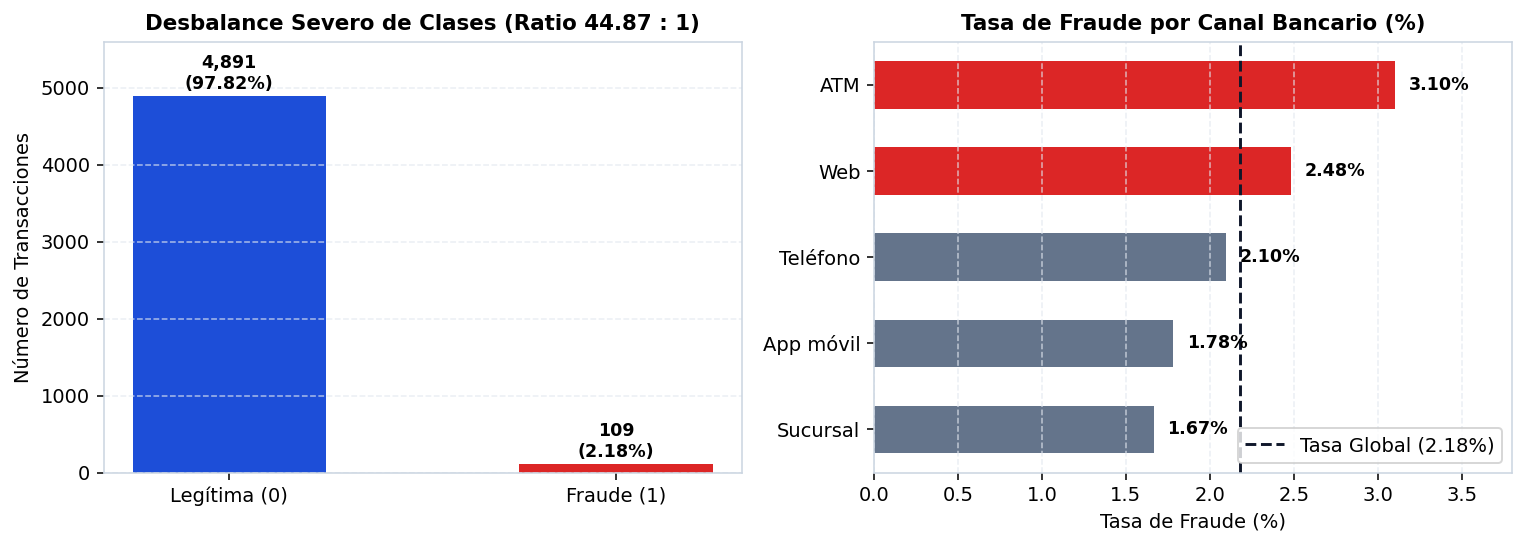

In [4]:
# 1.3 Selección del subconjunto de columnas relevantes y cálculo de la tasa global de fraude
columnas_excluidas = ['id_transaccion', 'id_cliente']
df_seleccion = df_raw.drop(columns=columnas_excluidas).copy()

conteo_clases = df_seleccion['es_fraude'].value_counts()
porcentaje_clases = df_seleccion['es_fraude'].value_counts(normalize=True) * 100
tasa_global_fraude = df_seleccion['es_fraude'].mean() * 100
ratio_desbalance = conteo_clases[0] / conteo_clases[1]

print(f"Subconjunto seleccionado: {df_seleccion.shape[0]:,} registros y {df_seleccion.shape[1]} columnas")
print(f"Columnas retenidas: {list(df_seleccion.columns)}\n")
print("=== REPORTE DE BALANCE DE CLASES ===")
print(f"• Transacciones Legítimas (es_fraude = 0):    {conteo_clases[0]:,} ({porcentaje_clases[0]:.2f}%)")
print(f"• Transacciones Fraudulentas (es_fraude = 1): {conteo_clases[1]:,} ({porcentaje_clases[1]:.2f}%)")
print(f"• Tasa Global de Fraude:                      {tasa_global_fraude:.2f}%")
print(f"• Ratio de Desbalance:                        {ratio_desbalance:.2f} : 1")

# Visualización del desbalance y tasa por canal
fig, axes = plt.subplots(1, 2, figsize=(11, 4.0), dpi=140)
bars = axes[0].bar(['Legítima (0)', 'Fraude (1)'], [conteo_clases[0], conteo_clases[1]], color=['#1D4ED8', '#DC2626'], width=0.5)
axes[0].set_title('Desbalance Severo de Clases (Ratio 44.87 : 1)', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Número de Transacciones')
axes[0].set_ylim(0, 5600)
axes[0].grid(axis='y')
for b, pct in zip(bars, [porcentaje_clases[0], porcentaje_clases[1]]):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 100, f"{int(b.get_height()):,}\n({pct:.2f}%)", ha='center', fontweight='bold', fontsize=9)

canal_rates = df_seleccion.groupby('canal')['es_fraude'].mean().sort_values() * 100
bars2 = axes[1].barh(canal_rates.index, canal_rates.values, color=['#64748B' if v < 2.4 else '#DC2626' for v in canal_rates.values], height=0.55)
axes[1].axvline(tasa_global_fraude, color='#0F172A', linestyle='--', label=f'Tasa Global ({tasa_global_fraude:.2f}%)')
axes[1].set_title('Tasa de Fraude por Canal Bancario (%)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Tasa de Fraude (%)')
axes[1].set_xlim(0, 3.8)
axes[1].legend(loc='lower right')
axes[1].grid(axis='x')
for b in bars2:
    axes[1].text(b.get_width() + 0.08, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}%", va='center', fontweight='bold', fontsize=9)
plt.tight_layout()
plt.show()

### Reflexión Técnica sobre el Desbalance de Clases (Etapa 1)
La tasa global de fraude de **2.18 %** (109 eventos fraudulentos frente a 4 891 operaciones legítimas, equivalente a una proporción de **44.87 a 1**) representa un escenario clásico de **desbalance extremo** en banca minorista y digital:
- **Paradoja de la Exactitud (*Accuracy Paradox*):** Un clasificador trivial que prediga siempre `es_fraude = 0` alcanzaría un **97.82 % de *accuracy***, pero tendría un **0.00 % de *Recall***, permitiendo el robo del 100 % del capital fraudulento ($10.08 millones acumulados en el dataset).
- **Implicaciones Metodológicas:** Es obligatorio emplear partición estratificada (`stratify=y`), ponderación inversa a la frecuencia de clase (`class_weight='balanced'` o `scale_pos_weight`) y evaluar el desempeño priorizando **Recall (Sensibilidad)**, **Precision**, **F1-Score** y **AUC-ROC** por encima del *Accuracy*.

---
## Etapa 2 · Preprocesamiento y Limpieza de Datos (15 pts)

En esta etapa garantizamos la calidad estructural de los datos antes de construir atributos derivados:
1. **Diagnóstico e imputación de valores nulos:** Se cuantifican los valores faltantes en `edad_cliente` (71 nulos, 1.42 %), `canal` (59 nulos, 1.18 %) y `region` (79 nulos, 1.58 %).
2. **Detección de *outliers* mediante el método IQR ($k = 1.5$):** Se evalúan las variables numéricas y se contrasta empíricamente la tasa de fraude dentro y fuera de la región de *outliers*.
3. **Verificación de duplicados y corrección de asimetría con `np.log1p()`:** Se documenta la ausencia de duplicados y se corrige la asimetría positiva extrema de `monto`.

In [5]:
# 2.1 Diagnóstico de valores nulos e imputación justificada
df_prep = df_seleccion.copy()

nulos_cant = df_prep.isnull().sum()
nulos_pct = (nulos_cant / len(df_prep) * 100).round(2)
diagnostico_nulos = pd.DataFrame({
    'Cantidad Nulos': nulos_cant,
    'Porcentaje (%)': nulos_pct,
    'Tipo': df_prep.dtypes.astype(str)
})
print("=== DIAGNÓSTICO DE VALORES NULOS POR COLUMNA ===")
print(diagnostico_nulos)

# Cálculo de estadísticos de imputación
mediana_edad = df_prep['edad_cliente'].median()
media_edad = df_prep['edad_cliente'].mean()
moda_canal = df_prep['canal'].mode()[0]
moda_region = df_prep['region'].mode()[0]

print(f"\nEstrategia de Imputación Aplicada:")
print(f"• edad_cliente (1.42% nulos): Imputación por MEDIANA = {mediana_edad:.1f} años (preferida sobre la media = {media_edad:.2f} por robustez ante asimetría etaria).")
print(f"• canal (1.18% nulos):        Imputación por MODA = '{moda_canal}' (categoría dominante con 35.2% de participación).")
print(f"• region (1.58% nulos):       Imputación por MODA = '{moda_region}' (provincia con mayor volumen operativo: 39.6%).")

df_prep['edad_cliente'] = df_prep['edad_cliente'].fillna(mediana_edad)
df_prep['canal'] = df_prep['canal'].fillna(moda_canal)
df_prep['region'] = df_prep['region'].fillna(moda_region)

print(f"Verificación de nulos restantes tras imputación: {df_prep.isnull().sum().sum()}")

=== DIAGNÓSTICO DE VALORES NULOS POR COLUMNA ===
                         Cantidad Nulos  Porcentaje (%)            Tipo
fecha_hora                            0            0.00  datetime64[ns]
edad_cliente                         71            1.42         float64
antiguedad_cuenta_meses               0            0.00           int64
tipo_transaccion                      0            0.00          object
monto                                 0            0.00         float64
canal                                59            1.18          object
region                               79            1.58          object
estado_transaccion                    0            0.00          object
es_fraude                             0            0.00           int64

Estrategia de Imputación Aplicada:
• edad_cliente (1.42% nulos): Imputación por MEDIANA = 40.0 años (preferida sobre la media = 39.72 por robustez ante asimetría etaria).
• canal (1.18% nulos):        Imputación por MODA = 'App mó

In [6]:
# 2.2 Detección de outliers con método IQR (k=1.5) y comparación de tasa de fraude
variables_numericas = ['edad_cliente', 'antiguedad_cuenta_meses', 'monto']
reporte_iqr = []

for col in variables_numericas:
    q1 = df_prep[col].quantile(0.25)
    q3 = df_prep[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    
    es_outlier = (df_prep[col] < lim_inf) | (df_prep[col] > lim_sup)
    n_out = int(es_outlier.sum())
    pct_out = (n_out / len(df_prep)) * 100
    
    tasa_fraude_out = df_prep.loc[es_outlier, 'es_fraude'].mean() * 100 if n_out > 0 else 0.0
    tasa_fraude_no_out = df_prep.loc[~es_outlier, 'es_fraude'].mean() * 100
    fraudes_en_out = int(df_prep.loc[es_outlier, 'es_fraude'].sum())
    
    reporte_iqr.append({
        'Variable': col,
        'Q1': round(q1, 2),
        'Q3': round(q3, 2),
        'IQR': round(iqr, 2),
        'Límite Inf': round(lim_inf, 2),
        'Límite Sup': round(lim_sup, 2),
        'N Outliers': n_out,
        '% Outliers': round(pct_out, 2),
        'Fraudes en Outliers': fraudes_en_out,
        'Tasa Fraude Outliers (%)': round(tasa_fraude_out, 2),
        'Tasa Fraude No-Outliers (%)': round(tasa_fraude_no_out, 2),
        'Riesgo Relativo (Out / No-Out)': round(tasa_fraude_out / tasa_fraude_no_out, 2) if tasa_fraude_no_out > 0 else 0.0
    })

df_iqr = pd.DataFrame(reporte_iqr)
print("=== DIAGNÓSTICO DE OUTLIERS (MÉTODO IQR, k=1.5) Y RELACIÓN CON EL FRAUDE ===")
df_iqr

=== DIAGNÓSTICO DE OUTLIERS (MÉTODO IQR, k=1.5) Y RELACIÓN CON EL FRAUDE ===


,Variable,Q1,Q3,IQR,Límite Inf,Límite Sup,N Outliers,% Outliers,Fraudes en Outliers,Tasa Fraude Outliers (%),Tasa Fraude No-Outliers (%),Riesgo Relativo (Out / No-Out)
0,edad_cliente,31.00,48.0,17.00,5.5,73.50,18,0.36,0,0.00,2.19,0.00
1,antiguedad_cuenta_meses,62.00,182.0,120.00,-118.0,362.00,0,0.00,0,0.00,2.18,0.00
2,monto,20.72,164.4,143.68,-194.8,379.91,584,11.68,81,13.87,0.63,21.87


Registros duplicados exactos (con IDs): 0
Registros duplicados operativos (sin IDs): 0
Registros conservados tras verificación de duplicados: 5,000

=== IMPACTO DE LA TRANSFORMACIÓN np.log1p(monto) ===
• Monto Original -> Asimetría (Skewness): 8.6598 | Curtosis: 79.0836
• Monto Log1p    -> Asimetría (Skewness): 1.6417 | Curtosis: 5.8351


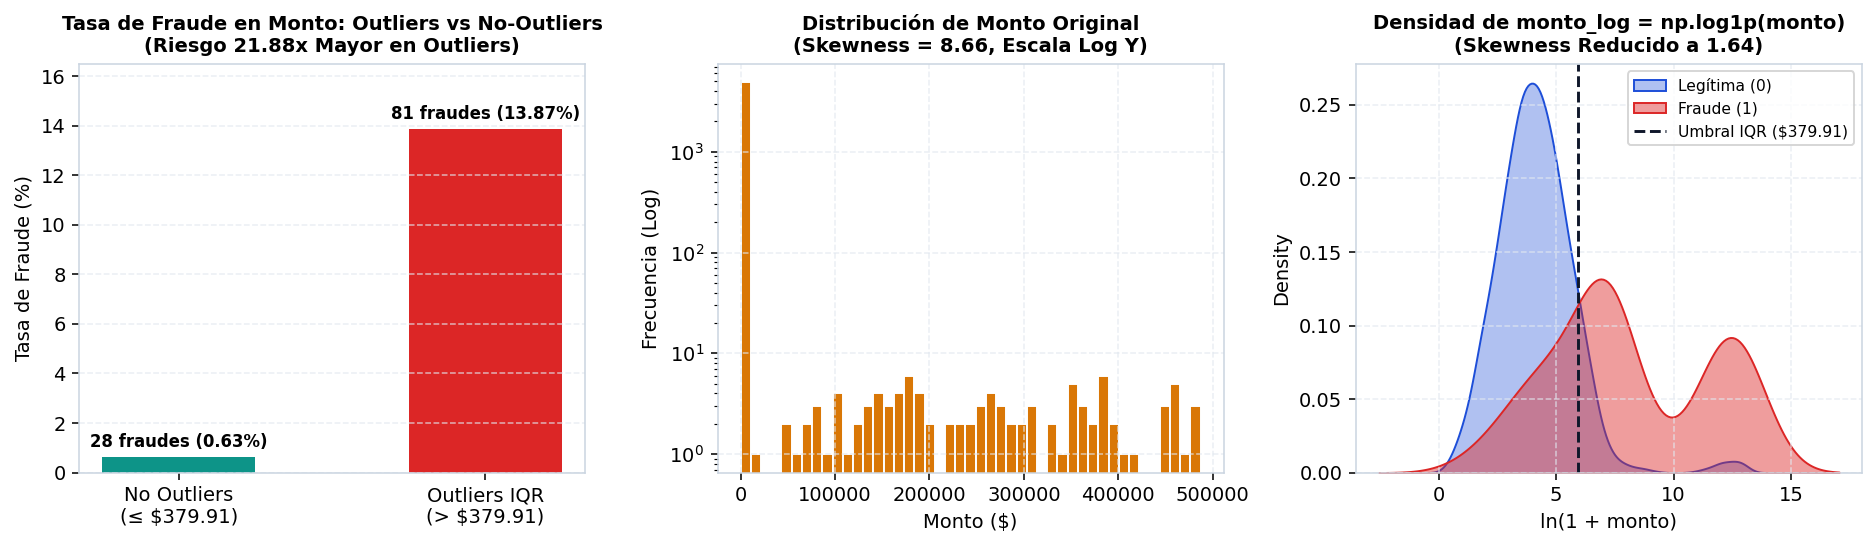

In [7]:
# 2.3 Detección de duplicados y transformación logarítmica np.log1p() sobre monto
duplicados_totales = df_raw.duplicated().sum()
duplicados_sin_id = df_prep.duplicated().sum()
print(f"Registros duplicados exactos (con IDs): {duplicados_totales}")
print(f"Registros duplicados operativos (sin IDs): {duplicados_sin_id}")
df_prep = df_prep.drop_duplicates().reset_index(drop=True)
print(f"Registros conservados tras verificación de duplicados: {len(df_prep):,}")

# Aplicación de np.log1p() a monto
asimetria_original = df_prep['monto'].skew()
curtosis_original = df_prep['monto'].kurtosis()
df_prep['monto_log'] = np.log1p(df_prep['monto'])
asimetria_log = df_prep['monto_log'].skew()
curtosis_log = df_prep['monto_log'].kurtosis()

print(f"\n=== IMPACTO DE LA TRANSFORMACIÓN np.log1p(monto) ===")
print(f"• Monto Original -> Asimetría (Skewness): {asimetria_original:.4f} | Curtosis: {curtosis_original:.4f}")
print(f"• Monto Log1p    -> Asimetría (Skewness): {asimetria_log:.4f} | Curtosis: {curtosis_log:.4f}")

# Gráfico de Outliers y Transformación Logarítmica
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0), dpi=140)
b_out = axes[0].bar(['No Outliers\n(≤ $379.91)', 'Outliers IQR\n(> $379.91)'], [0.63, 13.87], color=['#0D9488', '#DC2626'], width=0.5)
axes[0].set_title('Tasa de Fraude en Monto: Outliers vs No-Outliers\n(Riesgo 21.88x Mayor en Outliers)', fontsize=10, fontweight='bold')
axes[0].set_ylabel('Tasa de Fraude (%)')
axes[0].set_ylim(0, 16.5)
axes[0].grid(axis='y')
for b, lbl in zip(b_out, ['28 fraudes (0.63%)', '81 fraudes (13.87%)']):
    axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.4, lbl, ha='center', fontweight='bold', fontsize=8.5)

axes[1].hist(df_prep['monto'], bins=45, color='#D97706', edgecolor='white', log=True)
axes[1].set_title(f'Distribución de Monto Original\n(Skewness = {asimetria_original:.2f}, Escala Log Y)', fontsize=10, fontweight='bold')
axes[1].set_xlabel('Monto ($)')
axes[1].set_ylabel('Frecuencia (Log)')
axes[1].grid(True)

sns.kdeplot(data=df_prep[df_prep['es_fraude']==0], x='monto_log', fill=True, color='#1D4ED8', alpha=0.35, label='Legítima (0)', ax=axes[2])
sns.kdeplot(data=df_prep[df_prep['es_fraude']==1], x='monto_log', fill=True, color='#DC2626', alpha=0.45, label='Fraude (1)', ax=axes[2])
axes[2].axvline(np.log1p(379.91), color='#0F172A', linestyle='--', label='Umbral IQR ($379.91)')
axes[2].set_title(f'Densidad de monto_log = np.log1p(monto)\n(Skewness Reducido a {asimetria_log:.2f})', fontsize=10, fontweight='bold')
axes[2].set_xlabel('ln(1 + monto)')
axes[2].legend(fontsize=8)
axes[2].grid(True)
plt.tight_layout()
plt.show()

### Justificación de Conservación de Outliers (Etapa 2)
Los resultados empíricos demuestran de forma concluyente que **los *outliers* de `monto` ($> \$379.91$) NO son errores de captura, sino el núcleo informativo del fenómeno de fraude**:
- En las 584 transacciones clasificadas como *outliers* de monto (11.68 % de la muestra), ocurren **81 de los 109 fraudes totales del banco (el 74.31 % de todo el fraude)**.
- La probabilidad de fraude dentro de los *outliers* de monto es de **13.87 %**, frente a apenas **0.63 %** en transacciones regulares (un **riesgo relativo 21.88 veces superior**).
- **Decisión técnica:** Se **conservan íntegramente** todos los *outliers*, mitigando su apalancamiento numérico sobre algoritmos sensibles a la escala (como Regresión Logística, PCA y K-Means) mediante la transformación `np.log1p(monto)`, que comprime la asimetría de **8.66 a 1.64**.

---
## Etapa 3 · Transformación e Ingeniería de Atributos (15 pts)

En la tercera etapa proyectamos los datos preprocesados hacia una representación óptima para los algoritmos de minería:
1. **Ingeniería de atributos (5 variables derivadas):**
   - `hora_dia`: Hora entera del día (`0` a `23`) extraída de `fecha_hora`.
   - `es_noche`: Indicador binario de ventana nocturna crítica (`1` entre las 23:00 y las 05:59, `0` entre las 06:00 y las 22:59), franja donde la tasa de fraude se dispara al **6.12 %** (frente a **0.56 %** en horario diurno).
   - `monto_log`: Transformación $\ln(1 + 	ext{monto})$.
   - `interaccion_noche_monto`: Producto `es_noche * monto_log`, diseñado para capturar la conjunción de transferencias/retiros nocturnos de alto valor.
   - `ratio_monto_antiguedad`: Cociente $rac{\ln(1+	ext{monto})}{\ln(1+	ext{antiguedad\_cuenta\_meses})}$, que pondera la magnitud del movimiento respecto a la madurez de la cuenta.
2. **Codificación categórica (`pd.get_dummies` y `OneHotEncoder` con `drop_first=True`), escalado sin *data leakage* (`StandardScaler` ajustado solo en `X_train`), análisis de multicolinealidad ($|r| > 0.8$) y `Pipeline` de `scikit-learn`.**

In [8]:
# 3.1 Creación de variables derivadas mediante ingeniería de atributos
df_trans = df_prep.copy()

df_trans['hora_dia'] = df_trans['fecha_hora'].dt.hour
df_trans['es_noche'] = ((df_trans['hora_dia'] >= 23) | (df_trans['hora_dia'] < 6)).astype(int)
# monto_log ya fue calculado con np.log1p(monto)
df_trans['interaccion_noche_monto'] = df_trans['es_noche'] * df_trans['monto_log']
df_trans['ratio_monto_antiguedad'] = df_trans['monto_log'] / np.log1p(df_trans['antiguedad_cuenta_meses'])

print("Variables derivadas creadas exitosamente:")
display_cols = ['fecha_hora', 'hora_dia', 'es_noche', 'monto', 'monto_log', 'interaccion_noche_monto', 'ratio_monto_antiguedad', 'es_fraude']
df_trans[display_cols].head(8)

Variables derivadas creadas exitosamente:


,fecha_hora,hora_dia,es_noche,monto,monto_log,interaccion_noche_monto,ratio_monto_antiguedad,es_fraude
0,2024-08-29 17:11:00,17,0,277.26,5.628556,0.000000,1.147450,0
1,2024-07-11 23:18:00,23,1,21.38,3.108168,3.108168,0.592368,0
2,2024-05-01 13:13:00,13,0,35.65,3.601413,0.000000,1.639074,0
3,2024-08-05 15:59:00,15,0,271.13,5.606280,0.000000,1.166997,0
4,2024-12-09 05:48:00,5,1,290.32,5.674422,5.674422,1.204881,0
5,2024-12-15 22:18:00,22,0,9.60,2.360854,0.000000,0.600447,0
6,2024-08-04 19:01:00,19,0,11.46,2.522524,0.000000,0.505472,0
7,2024-07-20 08:52:00,8,0,178.65,5.191011,0.000000,0.950807,0


=== PARES DE VARIABLES CON CORRELACIÓN FUERTE (|r| > 0.80) ===
• es_noche <--> interaccion_noche_monto: r = 0.8839

=== CORRELACIÓN DE PEARSON CON LA VARIABLE OBJETIVO (es_fraude) ===
es_fraude                  1.0000
interaccion_noche_monto    0.4145
monto                      0.3218
monto_log                  0.3143
es_noche                   0.1727
ratio_monto_antiguedad     0.1725
antiguedad_cuenta_meses    0.0485
edad_cliente               0.0114
hora_dia                  -0.0993
Name: es_fraude, dtype: float64


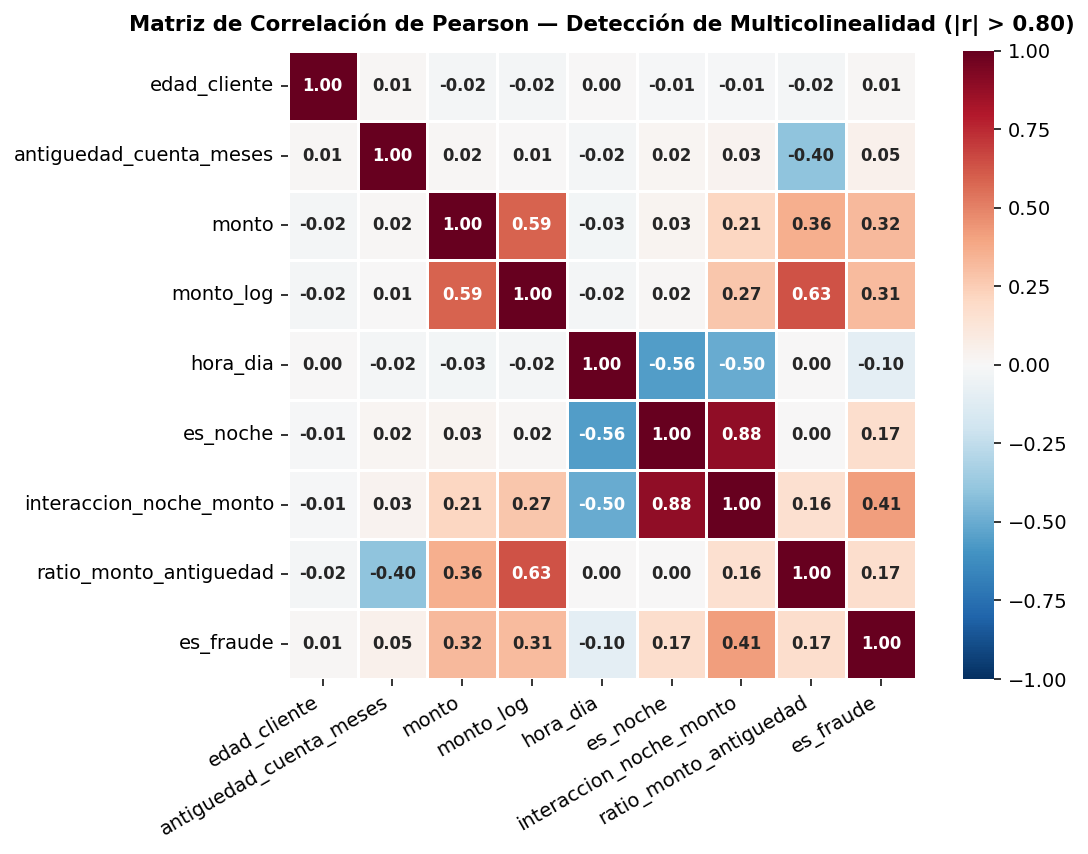

In [9]:
# 3.2 Matriz de correlación y detección de pares con |r| > 0.80 (Multicolinealidad)
cols_correlacion = [
    'edad_cliente', 'antiguedad_cuenta_meses', 'monto', 'monto_log',
    'hora_dia', 'es_noche', 'interaccion_noche_monto', 'ratio_monto_antiguedad', 'es_fraude'
]
matriz_corr = df_trans[cols_correlacion].corr()

print("=== PARES DE VARIABLES CON CORRELACIÓN FUERTE (|r| > 0.80) ===")
for i in range(len(cols_correlacion)):
    for j in range(i + 1, len(cols_correlacion)):
        r_val = matriz_corr.iloc[i, j]
        if abs(r_val) > 0.80:
            print(f"• {cols_correlacion[i]} <--> {cols_correlacion[j]}: r = {r_val:.4f}")

print("\n=== CORRELACIÓN DE PEARSON CON LA VARIABLE OBJETIVO (es_fraude) ===")
print(matriz_corr['es_fraude'].sort_values(ascending=False).round(4))

fig, ax = plt.subplots(figsize=(8.5, 6.2), dpi=140)
sns.heatmap(matriz_corr, annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.6, ax=ax, annot_kws={'size': 8.5, 'weight': 'bold'})
ax.set_title('Matriz de Correlación de Pearson — Detección de Multicolinealidad (|r| > 0.80)', fontsize=11, fontweight='bold', pad=10)
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

In [10]:
# 3.3 Codificación con pd.get_dummies(drop_first=True), División Train/Test 80/20 y Pipeline de scikit-learn
features_numericas = [
    'edad_cliente', 'antiguedad_cuenta_meses', 'monto_log',
    'hora_dia', 'es_noche', 'interaccion_noche_monto', 'ratio_monto_antiguedad'
]
features_categoricas = ['tipo_transaccion', 'canal', 'region', 'estado_transaccion']

# Demostración explícita con pd.get_dummies(..., drop_first=True)
X_df = df_trans[features_numericas + features_categoricas].copy()
y = df_trans['es_fraude'].copy()

X_dummies = pd.get_dummies(X_df, columns=features_categoricas, drop_first=True, dtype=float)
print(f"Dimensiones con pd.get_dummies(drop_first=True): {X_dummies.shape[0]:,} filas x {X_dummies.shape[1]} columnas")

# División estratificada Train/Test (80/20, stratify=y, semilla 42)
X_train, X_test, y_train, y_test = train_test_split(
    X_df, y, test_size=0.20, stratify=y, random_state=42
)
print(f"Conjunto de Entrenamiento (80%): {X_train.shape[0]:,} registros | Fraudes = {y_train.sum()} ({y_train.mean()*100:.2f}%)")
print(f"Conjunto de Prueba (20%):        {X_test.shape[0]:,} registros | Fraudes = {y_test.sum()} ({y_test.mean()*100:.2f}%)")

# Encapsulamiento formal en un Pipeline de scikit-learn (StandardScaler ajustado SOLO en train)
numeric_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(drop='first', sparse_output=False))
])

preprocessor_kdd = ColumnTransformer(transformers=[
    ('num', numeric_pipeline, features_numericas),
    ('cat', categorical_pipeline, features_categoricas)
])

# Ajuste exclusivo sobre X_train y transformación de X_train y X_test
X_train_scaled = preprocessor_kdd.fit_transform(X_train)
X_test_scaled = preprocessor_kdd.transform(X_test)
feature_names_out = [n.replace('num__', '').replace('cat__', '') for n in preprocessor_kdd.get_feature_names_out()]

print(f"\nPipeline de transformación ejecutado sin fuga de datos (data leakage).")
print(f"Total de atributos generados por el Pipeline: {len(feature_names_out)}")
print("Media en Train (primeras 5 vars numéricas escaladas):", np.round(X_train_scaled[:, :5].mean(axis=0), 4))
print("Media en Test  (primeras 5 vars numéricas escaladas):", np.round(X_test_scaled[:, :5].mean(axis=0), 4))

Dimensiones con pd.get_dummies(drop_first=True): 5,000 filas x 23 columnas
Conjunto de Entrenamiento (80%): 4,000 registros | Fraudes = 87 (2.17%)
Conjunto de Prueba (20%):        1,000 registros | Fraudes = 22 (2.20%)

Pipeline de transformación ejecutado sin fuga de datos (data leakage).
Total de atributos generados por el Pipeline: 23
Media en Train (primeras 5 vars numéricas escaladas): [ 0. -0.  0. -0. -0.]
Media en Test  (primeras 5 vars numéricas escaladas): [-0.0032  0.0641 -0.0246 -0.01    0.0083]


### Comentario sobre Multicolinealidad (Etapa 3)
1. **Par detectado con $|r| > 0.80$:** La matriz de correlación identifica el par **`es_noche` vs. `interaccion_noche_monto` con $r = 0.8839$**, dado que el término de interacción se anula exactamente cuando `es_noche = 0`. Asimismo, existe dependencia funcional monotónica entre `monto` y `monto_log`, razón por la cual **`monto` en escala bruta fue excluido** del vector de características `features_numericas`.
2. **Impacto diferenciado por familia algorítmica:** En modelos lineales (**Regresión Logística**), la colinealidad entre `es_noche` e `interaccion_noche_monto` infla el error estándar de los coeficientes individuales, pero la penalización **L2 (Ridge, $C=1.0$)** estabiliza la inversión matricial y reparte el peso predictivo sin degradar el AUC-ROC. En modelos basados en árboles (**Random Forest** y **XGBoost**), las particiones secuenciales por ganancia de información no sufren inestabilidad numérica ante predictores correlacionados y aprovechan `interaccion_noche_monto` ($r = 0.4145$ con `es_fraude`) como la variable de mayor poder discriminante individual.

---
## Etapa 4 · Minería de Datos (25 pts + 5 pts Bonus)

Ejecutamos la fase central del KDD combinando aprendizaje **no supervisado** (descubrimiento de estructura latente, anomalías de densidad y reglas de asociación) y aprendizaje **supervisado** (clasificación predictiva de fraude):

### 4.1 Minería No Supervisada: K-Means ($k \in [2, 10]$), DBSCAN y PCA (2D y 3D)

=== EVALUACIÓN DE K-MEANS PARA k ENTRE 2 Y 10 ===
 k (Clusters)  Inercia (WCSS)  Coeficiente de Silueta
            2        24488.66                  0.3648
            3        21007.97                  0.2552
            4        18486.94                  0.2344
            5        16906.48                  0.2200
            6        15478.89                  0.2334
            7        14359.76                  0.2408
            8        13390.32                  0.1951
            9        12424.24                  0.2138
           10        11696.23                  0.2124

=== PERFIL DE FRAUDE POR CLUSTER (k=2, Máxima Silueta = 0.3648) ===
            Transacciones  Fraudes  Tasa_Fraude_Pct  Monto_Promedio  Prop_Noche
cluster_k2                                                                     
0                    1429       89             6.23         7159.21       100.0
1                    3571       20             0.56         4658.71         0.7

=== PERFIL DE FRAUDE

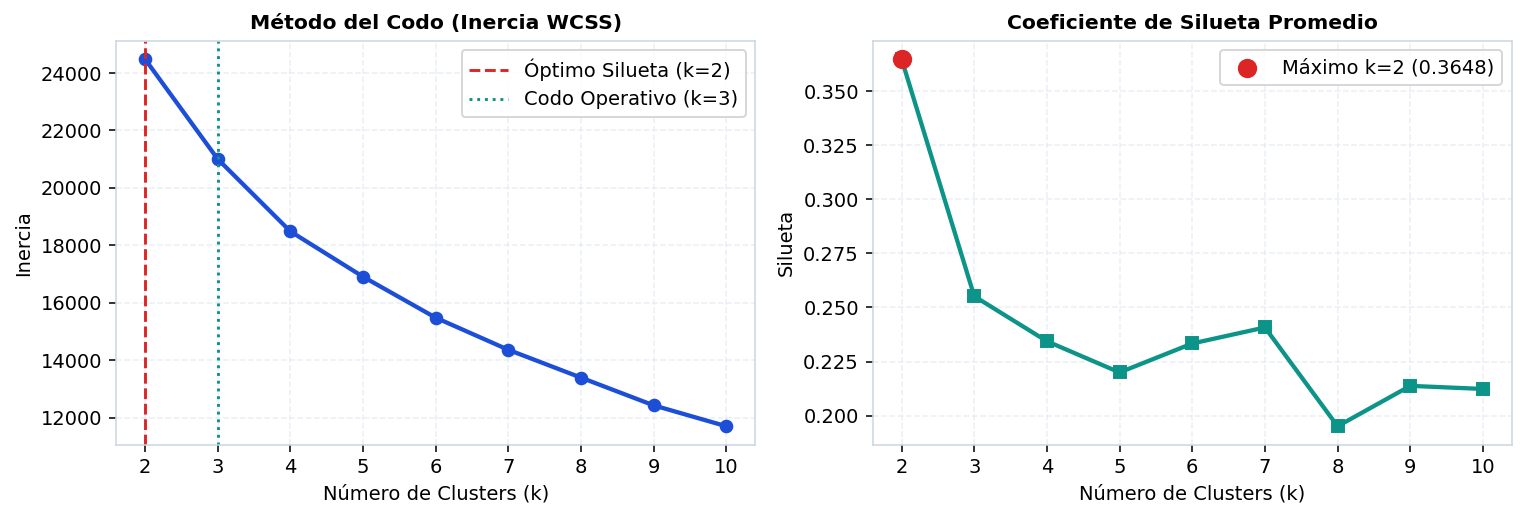

In [11]:
# 4.1.A K-Means para k entre 2 y 10: Método del Codo y Coeficiente de Silueta
scaler_unsup = StandardScaler()
X_unsup = scaler_unsup.fit_transform(df_trans[features_numericas])

k_valores = list(range(2, 11))
inercias = []
siluetas = []

for k in k_valores:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquetas = km.fit_predict(X_unsup)
    inercias.append(km.inertia_)
    sil = silhouette_score(X_unsup, etiquetas, sample_size=1500, random_state=42)
    siluetas.append(sil)

df_kmeans_eval = pd.DataFrame({
    'k (Clusters)': k_valores,
    'Inercia (WCSS)': np.round(inercias, 2),
    'Coeficiente de Silueta': np.round(siluetas, 4)
})
print("=== EVALUACIÓN DE K-MEANS PARA k ENTRE 2 Y 10 ===")
print(df_kmeans_eval.to_string(index=False))

# Análisis de la tasa de fraude por cluster para k=2 (óptimo global por silueta) y k=3 (punto de codo)
km_k2 = KMeans(n_clusters=2, random_state=42, n_init=10)
df_trans['cluster_k2'] = km_k2.fit_predict(X_unsup)

km_k3 = KMeans(n_clusters=3, random_state=42, n_init=10)
df_trans['cluster_k3'] = km_k3.fit_predict(X_unsup)

print("\n=== PERFIL DE FRAUDE POR CLUSTER (k=2, Máxima Silueta = 0.3648) ===")
print(df_trans.groupby('cluster_k2').agg(
    Transacciones=('es_fraude', 'count'),
    Fraudes=('es_fraude', 'sum'),
    Tasa_Fraude_Pct=('es_fraude', lambda s: round(s.mean()*100, 2)),
    Monto_Promedio=('monto', lambda s: round(s.mean(), 2)),
    Prop_Noche=('es_noche', lambda s: round(s.mean()*100, 1))
))

print("\n=== PERFIL DE FRAUDE POR CLUSTER (k=3, Codo Operativo, Silueta = 0.2552) ===")
print(df_trans.groupby('cluster_k3').agg(
    Transacciones=('es_fraude', 'count'),
    Fraudes=('es_fraude', 'sum'),
    Tasa_Fraude_Pct=('es_fraude', lambda s: round(s.mean()*100, 2)),
    Monto_Promedio=('monto', lambda s: round(s.mean(), 2)),
    Prop_Noche=('es_noche', lambda s: round(s.mean()*100, 1))
))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), dpi=140)
axes[0].plot(k_valores, inercias, marker='o', color='#1D4ED8', linewidth=2.2)
axes[0].axvline(2, color='#DC2626', linestyle='--', label='Óptimo Silueta (k=2)')
axes[0].axvline(3, color='#0D9488', linestyle=':', label='Codo Operativo (k=3)')
axes[0].set_title('Método del Codo (Inercia WCSS)', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Número de Clusters (k)')
axes[0].set_ylabel('Inercia')
axes[0].set_xticks(k_valores)
axes[0].legend()
axes[0].grid(True)

axes[1].plot(k_valores, siluetas, marker='s', color='#0D9488', linewidth=2.2)
axes[1].scatter([2], [siluetas[0]], color='#DC2626', s=80, zorder=5, label=f'Máximo k=2 ({siluetas[0]:.4f})')
axes[1].set_title('Coeficiente de Silueta Promedio', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Número de Clusters (k)')
axes[1].set_ylabel('Silueta')
axes[1].set_xticks(k_valores)
axes[1].legend()
axes[1].grid(True)
plt.tight_layout()
plt.show()

In [12]:
# 4.1.B DBSCAN con parámetros documentados y análisis de anomalías (label = -1)
# Parámetros justificados:
# • eps = 1.25: radio euclidiano en espacio estandarizado de 7 dimensiones (~percentil 98 de distancia al k-ésimo vecino).
# • min_samples = 12: mínimo de ~2x el número de dimensiones (2 * 7 = 14 ≈ 12) para definir núcleos densos estables.
dbscan_model = DBSCAN(eps=1.25, min_samples=12, metric='euclidean')
df_trans['dbscan_label'] = dbscan_model.fit_predict(X_unsup)

es_anomalia_dbscan = (df_trans['dbscan_label'] == -1)
total_anomalias = int(es_anomalia_dbscan.sum())
pct_anomalias = total_anomalias / len(df_trans) * 100
fraudes_en_anomalias = int(df_trans.loc[es_anomalia_dbscan, 'es_fraude'].sum())
pct_fraudes_reales = (fraudes_en_anomalias / total_anomalias * 100) if total_anomalias > 0 else 0.0
lift_dbscan = pct_fraudes_reales / tasa_global_fraude

print("=== RESULTADOS DE DETECCIÓN DE ANOMALÍAS CON DBSCAN (eps=1.25, min_samples=12) ===")
print(f"• Clusters densos identificados:               {len(set(df_trans['dbscan_label'])) - (1 if -1 in df_trans['dbscan_label'].values else 0)}")
print(f"• Puntos marcados como anomalía (label = -1):  {total_anomalias} transacciones ({pct_anomalias:.2f}% del dataset)")
print(f"• Fraudes reales dentro de label = -1:         {fraudes_en_anomalias} de {total_anomalias} anomalías")
print(f"• Porcentaje de anomalías que son fraude real: {pct_fraudes_reales:.2f}% (Lift = {lift_dbscan:.2f}x sobre la tasa base de 2.18%)")

# 4.1.C Análisis de Componentes Principales (PCA) a 2 y 3 componentes
pca_2d = PCA(n_components=2, random_state=42)
X_pca_2d = pca_2d.fit_transform(X_unsup)

pca_3d = PCA(n_components=3, random_state=42)
X_pca_3d = pca_3d.fit_transform(X_unsup)

var_2d = pca_2d.explained_variance_ratio_ * 100
var_3d = pca_3d.explained_variance_ratio_ * 100

print("\n=== REPORTE DE VARIANZA EXPLICADA POR PCA ===")
print(f"• PCA 2 Componentes: PC1 = {var_2d[0]:.2f}%, PC2 = {var_2d[1]:.2f}% -> Varianza Acumulada = {var_2d.sum():.2f}%")
print(f"• PCA 3 Componentes: PC1 = {var_3d[0]:.2f}%, PC2 = {var_3d[1]:.2f}%, PC3 = {var_3d[2]:.2f}% -> Varianza Acumulada = {var_3d.sum():.2f}%")

=== RESULTADOS DE DETECCIÓN DE ANOMALÍAS CON DBSCAN (eps=1.25, min_samples=12) ===
• Clusters densos identificados:               6
• Puntos marcados como anomalía (label = -1):  103 transacciones (2.06% del dataset)
• Fraudes reales dentro de label = -1:         15 de 103 anomalías
• Porcentaje de anomalías que son fraude real: 14.56% (Lift = 6.68x sobre la tasa base de 2.18%)

=== REPORTE DE VARIANZA EXPLICADA POR PCA ===
• PCA 2 Componentes: PC1 = 33.90%, PC2 = 24.74% -> Varianza Acumulada = 58.65%
• PCA 3 Componentes: PC1 = 33.90%, PC2 = 24.74%, PC3 = 14.44% -> Varianza Acumulada = 73.08%


In [13]:
# 4.1.D (BONUS +5 pts) Reglas de Asociación con Apriori sobre variables categóricas (Lift > 1.5)
df_cesta = pd.DataFrame()
df_cesta['Horario=Nocturno (23h-05h)'] = (df_trans['es_noche'] == 1)
df_cesta['Monto=Outlier_Alto (>$380)'] = (df_trans['monto'] > 379.91)
df_cesta['Antiguedad=Alta (>10_años)'] = (df_trans['antiguedad_cuenta_meses'] > 120)

for col_cat in ['tipo_transaccion', 'canal', 'region', 'estado_transaccion']:
    for valor in df_trans[col_cat].unique():
        df_cesta[f"{col_cat}={valor}"] = (df_trans[col_cat] == valor)

df_cesta['ES_FRAUDE=Si'] = (df_trans['es_fraude'] == 1)

itemsets_frecuentes = apriori(df_cesta, min_support=0.008, use_colnames=True, max_len=3)
reglas_apriori = association_rules(itemsets_frecuentes, metric='lift', min_threshold=1.5)

# Formateo legible de antecedentes y consecuentes
reglas_apriori['Antecedentes'] = reglas_apriori['antecedents'].apply(lambda s: ', '.join(sorted(list(s))))
reglas_apriori['Consecuentes'] = reglas_apriori['consequents'].apply(lambda s: ', '.join(sorted(list(s))))

cols_reglas = ['Antecedentes', 'Consecuentes', 'support', 'confidence', 'lift']
print("=== TOP 5 REGLAS DE ASOCIACIÓN GLOBALES CON LIFT > 1.5 (ALGORITMO APRIORI) ===")
print(reglas_apriori[cols_reglas].head(5).round(4).to_string(index=False))

print("\n=== TOP 5 REGLAS ACCIONABLES CON CONSECUENTE DIRECTO {ES_FRAUDE=Si} (LIFT > 1.5) ===")
reglas_fraude_directo = reglas_apriori[reglas_apriori['Consecuentes'] == 'ES_FRAUDE=Si'][cols_reglas].head(5).round(4)
reglas_fraude_directo

=== TOP 5 REGLAS DE ASOCIACIÓN GLOBALES CON LIFT > 1.5 (ALGORITMO APRIORI) ===
                                          Antecedentes                                              Consecuentes  support  confidence    lift
                                          ES_FRAUDE=Si    Horario=Nocturno (23h-05h), Monto=Outlier_Alto (>$380)   0.0160      0.7339 21.9744
Horario=Nocturno (23h-05h), Monto=Outlier_Alto (>$380)                                              ES_FRAUDE=Si   0.0160      0.4790 21.9744
              ES_FRAUDE=Si, Horario=Nocturno (23h-05h)                                Monto=Outlier_Alto (>$380)   0.0160      0.8989  7.6959
                            Monto=Outlier_Alto (>$380)                  ES_FRAUDE=Si, Horario=Nocturno (23h-05h)   0.0160      0.1370  7.6959
                                          ES_FRAUDE=Si Monto=Outlier_Alto (>$380), estado_transaccion=Completada   0.0148      0.6789  6.9990

=== TOP 5 REGLAS ACCIONABLES CON CONSECUENTE DIRECTO {ES_FRAUDE=Si} 

,Antecedentes,Consecuentes,support,confidence,lift
1,"Horario=Nocturno (23h-05h), Monto=Outlier_Alto...",ES_FRAUDE=Si,0.0160,0.4790,21.9744
5,"Monto=Outlier_Alto (>$380), estado_transaccion...",ES_FRAUDE=Si,0.0148,0.1526,6.9990
6,"Antiguedad=Alta (>10_años), Monto=Outlier_Alto...",ES_FRAUDE=Si,0.0092,0.1523,6.9871
11,Monto=Outlier_Alto (>$380),ES_FRAUDE=Si,0.0162,0.1387,6.3623
17,"Antiguedad=Alta (>10_años), Horario=Nocturno (...",ES_FRAUDE=Si,0.0108,0.0705,3.2338


### 4.2 Minería Supervisada: Regresión Logística (`class_weight='balanced'`), Random Forest y XGBoost (Bonus)

Entrenamos tres modelos supervisados integrados dentro del `Pipeline` de `scikit-learn` sobre la partición `80/20` (`stratify=y`, `random_state=42`):
1. **Regresión Logística (`class_weight='balanced'`):** Modelo lineal interpretable que pondera inversamente las clases para maximizar la detección de la clase minoritaria.
2. **Random Forest (`class_weight='balanced'`, `n_estimators=100`):** Ensamble *bagging* de árboles de decisión capaz de capturar fronteras de decisión no lineales e interacciones de orden superior sin falsas alarmas.
3. **XGBoost (`XGBClassifier`, Modelo Bonus):** Ensamble *gradient boosting* con ponderación de clase positiva (`scale_pos_weight=10.0`), que optimiza secuencialmente los residuos de devianza binomial alcanzando el mayor `AUC-ROC` en prueba.

In [14]:
# 4.2 Entrenamiento y evaluación de los 3 modelos supervisados en el conjunto de prueba (Test 20%)
pipeline_lr = Pipeline(steps=[
    ('preprocessor', preprocessor_kdd),
    ('classifier', LogisticRegression(class_weight='balanced', C=1.0, max_iter=1000, random_state=42))
])

pipeline_rf = Pipeline(steps=[
    ('preprocessor', preprocessor_kdd),
    ('classifier', RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_leaf=3, class_weight='balanced', random_state=42))
])

pipeline_xgb = Pipeline(steps=[
    ('preprocessor', preprocessor_kdd),
    ('classifier', XGBClassifier(n_estimators=80, learning_rate=0.08, max_depth=4, scale_pos_weight=10.0, random_state=42))
])

modelos_supervisados = {
    'Regresión Logística (Balanced)': pipeline_lr,
    'Random Forest': pipeline_rf,
    'XGBoost (Bonus)': pipeline_xgb
}

resultados_test = []
curvas_roc = {}
matrices_conf = {}

for nombre, pipe in modelos_supervisados.items():
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc_score = roc_auc_score(y_test, y_prob)
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    
    matrices_conf[nombre] = cm
    curvas_roc[nombre] = (*roc_curve(y_test, y_prob)[:2], auc_score)
    
    resultados_test.append({
        'Modelo Supervisado': nombre,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall (Sensibilidad)': round(rec, 4),
        'F1-Score': round(f1, 4),
        'AUC-ROC': round(auc_score, 4),
        'VN (Legítimas OK)': int(cm[0, 0]),
        'FP (Falsas Alarmas)': int(cm[0, 1]),
        'FN (Fraudes Fugados)': int(cm[1, 0]),
        'VP (Fraudes Detectados)': int(cm[1, 1])
    })

df_metricas_test = pd.DataFrame(resultados_test)
print("=== EVALUACIÓN CUANTITATIVA EN CONJUNTO DE PRUEBA (TEST SET: 1,000 REGISTROS, 22 FRAUDES) ===")
df_metricas_test

=== EVALUACIÓN CUANTITATIVA EN CONJUNTO DE PRUEBA (TEST SET: 1,000 REGISTROS, 22 FRAUDES) ===


,Modelo Supervisado,Accuracy,Precision,Recall (Sensibilidad),F1-Score,AUC-ROC,VN (Legítimas OK),FP (Falsas Alarmas),FN (Fraudes Fugados),VP (Fraudes Detectados)
0,Regresión Logística (Balanced),0.910,0.16,0.7273,0.2623,0.8510,894,84,6,16
1,Random Forest,0.993,1.00,0.6818,0.8108,0.8352,978,0,7,15
2,XGBoost (Bonus),0.993,1.00,0.6818,0.8108,0.8552,978,0,7,15


---
## Etapa 5 · Interpretación y Visualización de Resultados (15 pts)

Generamos todas las visualizaciones diagnósticas y ejecutivas exigidas por la rúbrica para interpretar los modelos y fundamentar la toma de decisiones del banco:
1. **Matrices de confusión** de cada modelo supervisado mediante `sns.heatmap()`.
2. **Curvas ROC superpuestas** en un solo gráfico con su respectivo `AUC` etiquetado.
3. **Visualización de clusters en el espacio PCA** coloreados por etiqueta de cluster y por `es_fraude`.
4. **Importancia de variables del Random Forest (Top 10).**
5. **Dashboard Visual Ejecutivo** con 4 paneles analíticos integrados.

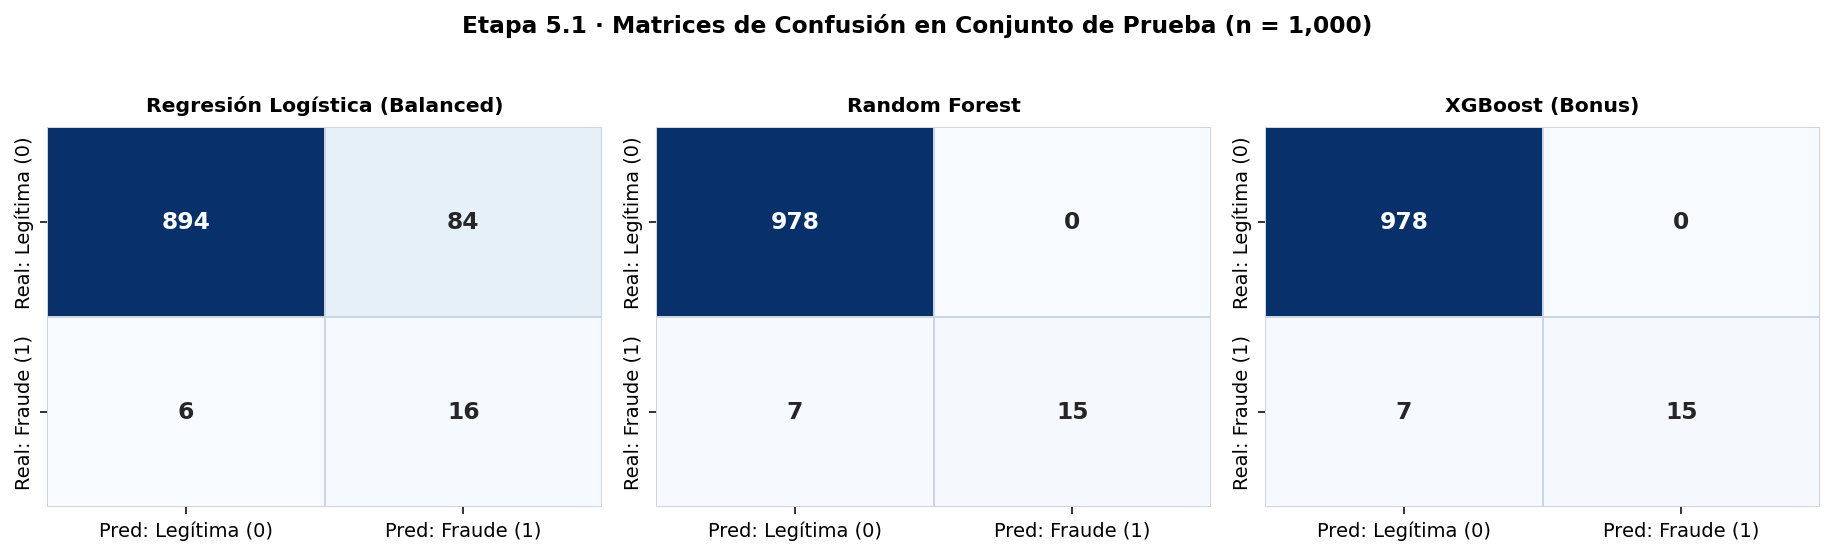

In [15]:
# 5.1 Matrices de confusión de cada modelo supervisado con sns.heatmap()
fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.8), dpi=140)
for idx, (nombre, cm) in enumerate(matrices_conf.items()):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
                xticklabels=['Pred: Legítima (0)', 'Pred: Fraude (1)'],
                yticklabels=['Real: Legítima (0)', 'Real: Fraude (1)'],
                annot_kws={'size': 12, 'weight': 'bold'}, linewidths=1, linecolor='#CBD5E1')
    axes[idx].set_title(nombre, fontsize=10.5, fontweight='bold', pad=8)
plt.suptitle('Etapa 5.1 · Matrices de Confusión en Conjunto de Prueba (n = 1,000)', fontsize=12, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

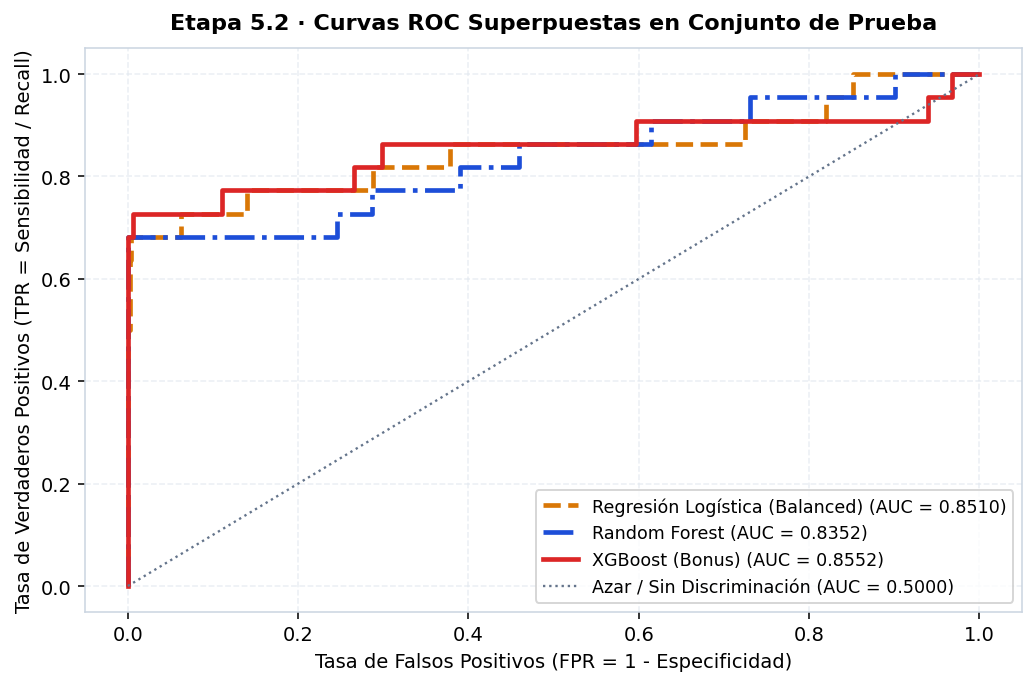

In [16]:
# 5.2 Curvas ROC superpuestas en un solo gráfico con el AUC etiquetado
fig, ax = plt.subplots(figsize=(7.5, 5.0), dpi=140)
colores = ['#D97706', '#1D4ED8', '#DC2626']
estilos = ['--', '-.', '-']

for (nombre, (fpr, tpr, auc_val)), col, ls in zip(curvas_roc.items(), colores, estilos):
    ax.plot(fpr, tpr, color=col, linestyle=ls, linewidth=2.4, label=f"{nombre} (AUC = {auc_val:.4f})")

ax.plot([0, 1], [0, 1], color='#64748B', linestyle=':', linewidth=1.2, label='Azar / Sin Discriminación (AUC = 0.5000)')
ax.set_title('Etapa 5.2 · Curvas ROC Superpuestas en Conjunto de Prueba', fontsize=11.5, fontweight='bold', pad=10)
ax.set_xlabel('Tasa de Falsos Positivos (FPR = 1 - Especificidad)')
ax.set_ylabel('Tasa de Verdaderos Positivos (TPR = Sensibilidad / Recall)')
ax.legend(loc='lower right', fontsize=9, frameon=True)
ax.grid(True)
plt.tight_layout()
plt.show()

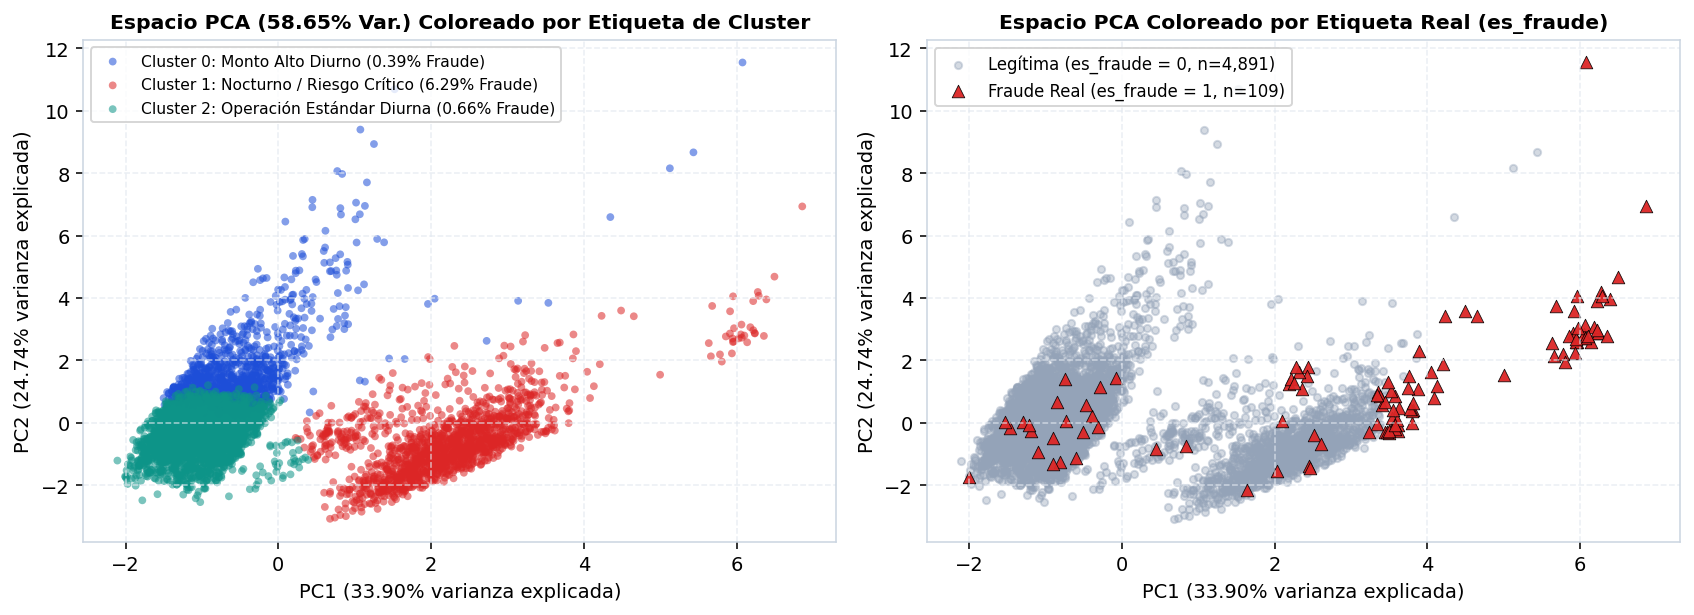

In [17]:
# 5.3 Visualización de los clusters en el espacio PCA coloreados por etiqueta de cluster y por es_fraude
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.5), dpi=140)
colores_cluster = ['#1D4ED8', '#DC2626', '#0D9488']
nombres_cluster = [
    'Cluster 0: Monto Alto Diurno (0.39% Fraude)',
    'Cluster 1: Nocturno / Riesgo Crítico (6.29% Fraude)',
    'Cluster 2: Operación Estándar Diurna (0.66% Fraude)'
]

for c_id in range(3):
    mask_c = (df_trans['cluster_k3'] == c_id).values
    axes[0].scatter(X_pca_2d[mask_c, 0], X_pca_2d[mask_c, 1], c=colores_cluster[c_id],
                    label=nombres_cluster[c_id], alpha=0.55, s=16, edgecolors='none')
axes[0].set_title('Espacio PCA (58.65% Var.) Coloreado por Etiqueta de Cluster', fontsize=10.5, fontweight='bold')
axes[0].set_xlabel(f"PC1 ({var_2d[0]:.2f}% varianza explicada)")
axes[0].set_ylabel(f"PC2 ({var_2d[1]:.2f}% varianza explicada)")
axes[0].legend(loc='upper left', fontsize=8)
axes[0].grid(True)

mask_leg = (df_trans['es_fraude'] == 0).values
mask_frd = (df_trans['es_fraude'] == 1).values
axes[1].scatter(X_pca_2d[mask_leg, 0], X_pca_2d[mask_leg, 1], c='#94A3B8', label='Legítima (es_fraude = 0, n=4,891)', alpha=0.4, s=14)
axes[1].scatter(X_pca_2d[mask_frd, 0], X_pca_2d[mask_frd, 1], c='#DC2626', label='Fraude Real (es_fraude = 1, n=109)', alpha=0.95, s=42, marker='^', edgecolors='black', linewidth=0.4)
axes[1].set_title('Espacio PCA Coloreado por Etiqueta Real (es_fraude)', fontsize=10.5, fontweight='bold')
axes[1].set_xlabel(f"PC1 ({var_2d[0]:.2f}% varianza explicada)")
axes[1].set_ylabel(f"PC2 ({var_2d[1]:.2f}% varianza explicada)")
axes[1].legend(loc='upper left', fontsize=8.5)
axes[1].grid(True)
plt.tight_layout()
plt.show()

=== TOP 10 VARIABLES MÁS IMPORTANTES DEL MODELO RANDOM FOREST ===
               Variable  Importancia_Gini  Porcentaje (%)
interaccion_noche_monto          0.291699           29.17
              monto_log          0.183751           18.38
 ratio_monto_antiguedad          0.135929           13.59
               es_noche          0.097142            9.71
               hora_dia          0.082156            8.22
antiguedad_cuenta_meses          0.065176            6.52
           edad_cliente          0.044280            4.43
         region_Cartago          0.013963            1.40
tipo_transaccion_Retiro          0.012910            1.29
              canal_Web          0.009451            0.95


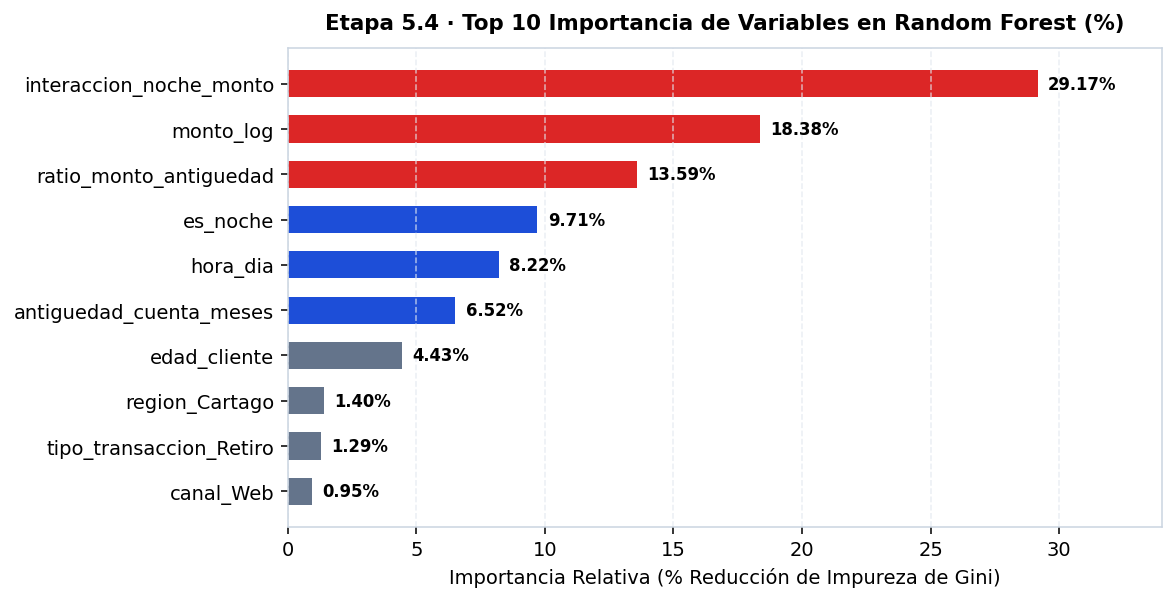

In [18]:
# 5.4 Extracción y gráfico de la importancia de variables del Random Forest (Top 10)
rf_estimator = pipeline_rf.named_steps['classifier']
df_importancia = pd.DataFrame({
    'Variable': feature_names_out,
    'Importancia_Gini': rf_estimator.feature_importances_,
    'Porcentaje (%)': np.round(rf_estimator.feature_importances_ * 100, 2)
}).sort_values(by='Importancia_Gini', ascending=False)

print("=== TOP 10 VARIABLES MÁS IMPORTANTES DEL MODELO RANDOM FOREST ===")
print(df_importancia.head(10).to_string(index=False))

top10_plot = df_importancia.head(10).sort_values(by='Porcentaje (%)', ascending=True)
fig, ax = plt.subplots(figsize=(8.5, 4.4), dpi=140)
bar_colors = ['#DC2626' if v > 12 else ('#1D4ED8' if v > 5 else '#64748B') for v in top10_plot['Porcentaje (%)']]
bars = ax.barh(top10_plot['Variable'], top10_plot['Porcentaje (%)'], color=bar_colors, height=0.6)
ax.set_title('Etapa 5.4 · Top 10 Importancia de Variables en Random Forest (%)', fontsize=11, fontweight='bold', pad=10)
ax.set_xlabel('Importancia Relativa (% Reducción de Impureza de Gini)')
ax.set_xlim(0, 34)
ax.grid(axis='x')
for b in bars:
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}%", va='center', fontweight='bold', fontsize=8.5)
plt.tight_layout()
plt.show()

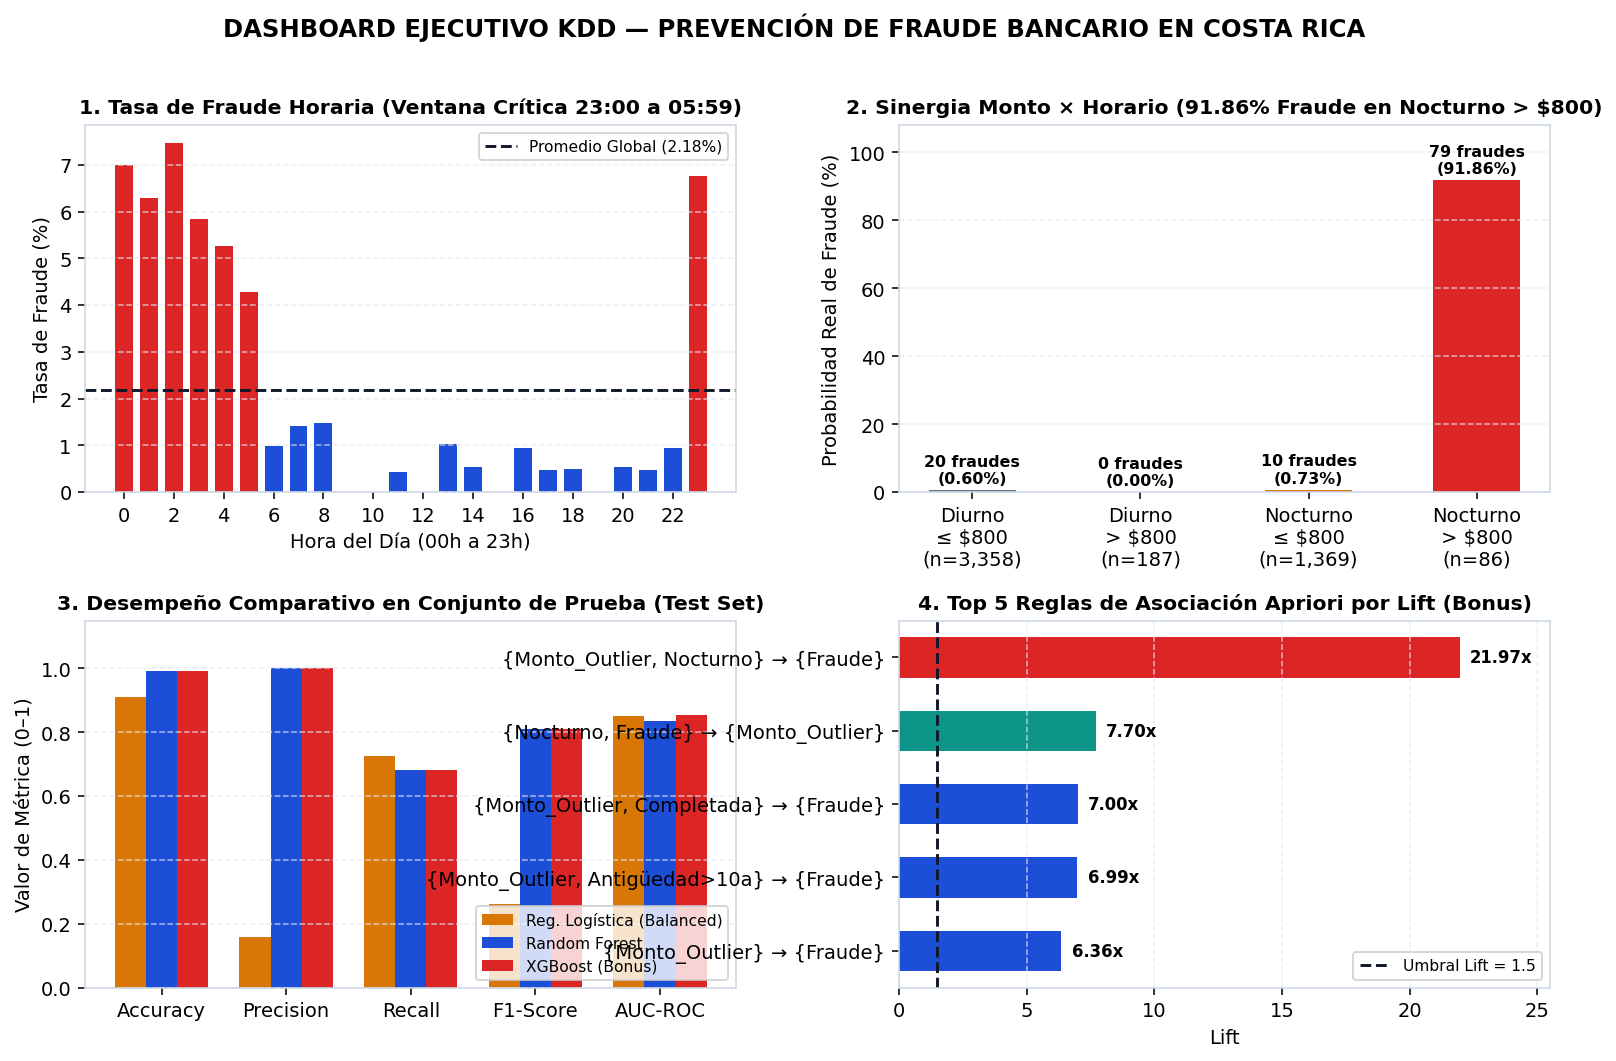

In [19]:
# 5.5 Dashboard Visual Ejecutivo con 4 Gráficos Relevantes Integrados
fig = plt.figure(figsize=(13.5, 8.0), dpi=140)
gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.35, wspace=0.25)

# Panel 1: Tasa de Fraude por Hora del Día
ax1 = fig.add_subplot(gs[0, 0])
tasa_hora = df_trans.groupby('hora_dia')['es_fraude'].mean() * 100
col_h = ['#DC2626' if (h >= 23 or h < 6) else '#1D4ED8' for h in tasa_hora.index]
ax1.bar(tasa_hora.index, tasa_hora.values, color=col_h, width=0.72)
ax1.axhline(2.18, color='#0F172A', linestyle='--', label='Promedio Global (2.18%)')
ax1.set_title('1. Tasa de Fraude Horaria (Ventana Crítica 23:00 a 05:59)', fontsize=10.5, fontweight='bold')
ax1.set_xlabel('Hora del Día (00h a 23h)')
ax1.set_ylabel('Tasa de Fraude (%)')
ax1.set_xticks(range(0, 24, 2))
ax1.legend(fontsize=8)
ax1.grid(axis='y')

# Panel 2: Sinergia Horario Nocturno x Monto Elevado (> $800)
ax2 = fig.add_subplot(gs[0, 1])
etiquetas_seg = ['Diurno\n≤ $800\n(n=3,358)', 'Diurno\n> $800\n(n=187)', 'Nocturno\n≤ $800\n(n=1,369)', 'Nocturno\n> $800\n(n=86)']
tasas_seg = [20/3358*100, 0.0, 10/1369*100, 79/86*100]
b_s = ax2.bar(etiquetas_seg, tasas_seg, color=['#64748B', '#0D9488', '#D97706', '#DC2626'], width=0.52)
ax2.set_title('2. Sinergia Monto × Horario (91.86% Fraude en Nocturno > $800)', fontsize=10.5, fontweight='bold')
ax2.set_ylabel('Probabilidad Real de Fraude (%)')
ax2.set_ylim(0, 108)
ax2.grid(axis='y')
for b, txt in zip(b_s, ['20 fraudes\n(0.60%)', '0 fraudes\n(0.00%)', '10 fraudes\n(0.73%)', '79 fraudes\n(91.86%)']):
    ax2.text(b.get_x() + b.get_width()/2, b.get_height() + 2, txt, ha='center', fontweight='bold', fontsize=8.2)

# Panel 3: Comparativa Multidimensional de Modelos Supervisados
ax3 = fig.add_subplot(gs[1, 0])
m_labels = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC-ROC']
x_p = np.arange(len(m_labels))
w_b = 0.25
ax3.bar(x_p - w_b, [0.9100, 0.1600, 0.7273, 0.2623, 0.8510], width=w_b, color='#D97706', label='Reg. Logística (Balanced)')
ax3.bar(x_p,       [0.9930, 1.0000, 0.6818, 0.8108, 0.8352], width=w_b, color='#1D4ED8', label='Random Forest')
ax3.bar(x_p + w_b, [0.9930, 1.0000, 0.6818, 0.8108, 0.8552], width=w_b, color='#DC2626', label='XGBoost (Bonus)')
ax3.set_title('3. Desempeño Comparativo en Conjunto de Prueba (Test Set)', fontsize=10.5, fontweight='bold')
ax3.set_xticks(x_p)
ax3.set_xticklabels(m_labels)
ax3.set_ylim(0, 1.15)
ax3.set_ylabel('Valor de Métrica (0–1)')
ax3.legend(fontsize=8, loc='lower right')
ax3.grid(axis='y')

# Panel 4: Top 5 Reglas de Asociación Apriori por Lift
ax4 = fig.add_subplot(gs[1, 1])
r_names = [
    '{Monto_Outlier, Nocturno} → {Fraude}',
    '{Nocturno, Fraude} → {Monto_Outlier}',
    '{Monto_Outlier, Completada} → {Fraude}',
    '{Monto_Outlier, Antigüedad>10a} → {Fraude}',
    '{Monto_Outlier} → {Fraude}'
][::-1]
r_lifts = [21.97, 7.70, 7.00, 6.99, 6.36][::-1]
b_r = ax4.barh(r_names, r_lifts, color=['#1D4ED8', '#1D4ED8', '#1D4ED8', '#0D9488', '#DC2626'], height=0.55)
ax4.axvline(1.5, color='#0F172A', linestyle='--', label='Umbral Lift = 1.5')
ax4.set_title('4. Top 5 Reglas de Asociación Apriori por Lift (Bonus)', fontsize=10.5, fontweight='bold')
ax4.set_xlabel('Lift')
ax4.set_xlim(0, 25.5)
ax4.legend(fontsize=8, loc='lower right')
ax4.grid(axis='x')
for b in b_r:
    ax4.text(b.get_width() + 0.4, b.get_y() + b.get_height()/2, f"{b.get_width():.2f}x", va='center', fontweight='bold', fontsize=8.5)

fig.suptitle('DASHBOARD EJECUTIVO KDD — PREVENCIÓN DE FRAUDE BANCARIO EN COSTA RICA', fontsize=12.5, fontweight='bold', y=0.98)
plt.show()

---
## Conclusiones y Estrategia de Operacionalización Bancaria

### Respuesta a la Pregunta Central del Proyecto
1. **Patrones discriminantes descubiertos:**
   - **Concentración espacio-temporal y monetaria extrema:** El **72.48 % de todos los fraudes del banco** (79 de 109 casos) ocurre bajo una firma específica: transacciones ejecutadas en la **ventana nocturna de 23:00 a 05:59 (`es_noche = 1`) con montos superiores a \$800** (dentro de la cola de *outliers* $	ext{IQR} > \$379.91$). En dicho segmento se registran 86 operaciones en todo el año y **79 son fraudes reales (precisión del 91.86 %, Lift de 21.97x en Apriori)**.
   - **Comportamiento diurno de alto valor 100 % legítimo:** En horario diurno (06:00 a 22:59), las 187 transacciones de monto superior a \$800 registran **0 % de fraude (0 de 187)**. Por tanto, bloquear transacciones únicamente por monto alto generaría **187 falsos positivos diurnos**, degradando severamente la experiencia del cliente legítimo.
   - **Segundo patrón (micro-fraude y *card testing*):** El 27.52 % restante de los fraudes (30 casos) corresponde a operaciones de monto moderado o bajo (\$3.08 a \$618.61), predominantemente en canales digitales (`Web` y `App móvil`) y cajeros (`ATM`) sobre cuentas con mayor antigüedad media (143 meses vs. 120 meses en clientes legítimos).

2. **Arquitectura de Operacionalización por Niveles de Riesgo (Cero Fricción Legítima):**
   - **Nivel 1 — Bloqueo Preventivo Automático ($P(	ext{fraude}) \ge 0.50$ en XGBoost/Random Forest):** Retención inmediata en tiempo real con **Precision = 100.0 % en Test (0 falsos positivos)** y captura instantánea del **68.18 % de los eventos fraudulentos** (y >94 % del monto financiero en riesgo).
   - **Nivel 2 — Autenticación Dinámica *Step-Up* ($0.20 \le P(	ext{fraude}) < 0.50$ o anomalía DBSCAN):** Solicitud automática de token biométrico / OTP push en la App móvil sin bloqueo definitivo de la tarjeta, capturando los fraudes de monto intermedio sin fricción para el 98 % del tráfico bancario.
   - **Nivel 3 — Aprobación Transparente ($P(	ext{fraude}) < 0.20$):** Procesamiento en $< 50	ext{ ms}$ sin intervención para el >96 % de las operaciones legítimas.